In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DistanceProject import DistanceAnalysis, create_new_result_dir
from DistancePlots import plot_repeats, plot_trials, plot_raw_traces, plot_trials_ordered, plot_reliability_distribution, plot_trials_ordered_2, plot_boxplot, plot_RF_vs_modulation
import os
import pickle

%load_ext autoreload
%autoreload 2

data_dir = r'D:/data-distance-coding-project/processed-data'

In [4]:
# imaging_filenames = [r'240703_SAM019', r'240708_SAM019_1', r'240708_SAM019_2', r'240710_SAM019_RL', r'240719_SAM019', r'240724_SAM019_1', r'240724_SAM019_2', r'240731_SAM019_1', 
#                      r'240731_SAM019_2_HVA']
imaging_filenames = [r'240703_SAM019', r'240708_SAM019_1', r'240708_SAM019_2', r'240724_SAM019_1', r'240731_SAM019_1']

results_directories = []
for imaging_filename in imaging_filenames:
    results_directories.append(data_dir + '/' + str(imaging_filename) + '/results')

In [3]:
print(results_directories)

['D:/data-distance-coding-project/processed-data/240703_SAM019/results', 'D:/data-distance-coding-project/processed-data/240708_SAM019_1/results', 'D:/data-distance-coding-project/processed-data/240708_SAM019_2/results', 'D:/data-distance-coding-project/processed-data/240724_SAM019_1/results', 'D:/data-distance-coding-project/processed-data/240731_SAM019_1/results']


In [14]:
DffData = []
SpikeData = []
for imaging_filename in imaging_filenames:
    imaging_dir = os.path.join(data_dir, imaging_filename)
    object_filename_dff = imaging_dir + '/' + imaging_filename + '_distance.pkl'
    object_filename_spikes = imaging_dir + '/' + imaging_filename + '_distance_spikes.pkl'
    # import the data
    with open(object_filename_dff, 'rb') as f:
        D = pickle.load(f)
        D.extract_characteristics_all()
        print('Loaded DistanceAnalysis object')
    
    with open(object_filename_spikes, 'rb') as f:
        S = pickle.load(f)
        S.extract_characteristics_all()
        print('Loaded DistanceAnalysis object with spikes')
    
    DffData.append(D)
    SpikeData.append(S)

 Cell 509Loaded DistanceAnalysis object
 Cell 509Loaded DistanceAnalysis object with spikes
 Cell 560Loaded DistanceAnalysis object
 Cell 560Loaded DistanceAnalysis object with spikes
 Cell 537Loaded DistanceAnalysis object
 Cell 537Loaded DistanceAnalysis object with spikes
 Cell 377Loaded DistanceAnalysis object
 Cell 377Loaded DistanceAnalysis object with spikes
 Cell 616Loaded DistanceAnalysis object
 Cell 616Loaded DistanceAnalysis object with spikes


In [26]:
imaging_filenames_out_of_field = [r'240710_SAM019_RL', r'240724_SAM019_2', r'240731_SAM019_2_HVA', r'240719_SAM019']

OutData = []

for imaging_filename in imaging_filenames_out_of_field:
    imaging_dir = os.path.join(data_dir, imaging_filename)
    object_filename = imaging_dir + '/' + imaging_filename + '_distance.pkl'
    # import the data
    with open(object_filename, 'rb') as f:
        D = pickle.load(f)
        print('Loaded DistanceAnalysis object')
    
    D.extract_characteristics_all()
    
    OutData.append(D)

Loaded DistanceAnalysis object
 Cell 271Loaded DistanceAnalysis object
 Cell 489Loaded DistanceAnalysis object
 Cell 575Loaded DistanceAnalysis object
 Cell 332

# Plot all Cells

In [23]:
saving_dir = os.path.join(data_dir, '000000_SAM019')

for i, D in enumerate(SpikeData):
    
    for cell in range(D.dFF.shape[0]):
        
        print('\r Current sessions: ' + D.path + ' cell ' + str(cell), end="")
        
        plot_trials_ordered_2(D, cell, title=imaging_filenames[i])
        
        if D.stats['type'][cell] == 'un-reliable':
            plt.savefig(saving_dir + '/un-reliable/' + imaging_filenames[i]+ '_' + str(cell) + '.png')
        elif D.stats['type'][cell] == 'un-modulated':
            plt.savefig(saving_dir + '/un-modulated/' + imaging_filenames[i]+ '_' + str(cell) + '.png')
        elif D.stats['type'][cell] == 'binocular':
            plt.savefig(saving_dir + '/binocular/' + imaging_filenames[i]+ '_' + str(cell) + '.png')
        elif D.stats['type'][cell] == 'monocular':
            plt.savefig(saving_dir + '/monocular/' + imaging_filenames[i]+ '_' + str(cell) + '.png')
        else:
            plt.savefig(saving_dir + '/both/' + imaging_filenames[i]+ '_' + str(cell) + '.png')
        
        plt.close()

 Current sessions: D:/data-distance-coding-project/processed-data\240731_SAM019_1 cell 616

# Type of modulation by session

In [27]:
import pandas as pd

# Compute counts and percentages
Data = OutData
categories = ['un-modulated', 'binocular', 'monocular']

cat_count = []
for D in Data:
    type = D.stats['type']
    counts = [type.count(cat) for cat in categories]
    cat_count.append(counts)

cat_pcgt = []
for count in cat_count:
    total_counts = sum(count)
    percentages = [i / total_counts * 100 for i in count]
    cat_pcgt.append(percentages)
    
for i in cat_count:
    print(sum(i))

29
194
127
127


([], [])

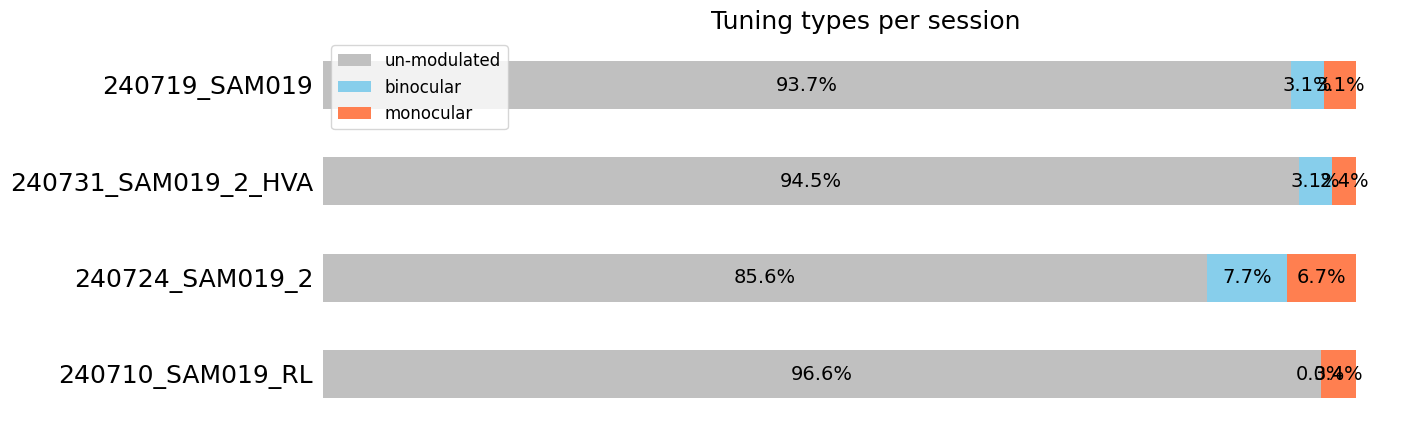

In [50]:
# do the session so that they have the sessions_filenames
data = {'Session': imaging_filenames_out_of_field}

for i, category in enumerate(categories):
    data[category] = [count[i] for count in cat_pcgt]

df = pd.DataFrame(data)

# Plot a Stacked Bar Chart using matplotlib
fig, ax = plt.subplots(figsize=(14, 5))  # Adjust the figsize to make the figure wider
df.set_index('Session').plot(
    kind='barh',
    stacked=True,
    title='Tuning types per session',
    mark_right=True,
    ax=ax,
    color=['silver', 'skyblue', 'coral', 'plum']
)

# Calculate total counts and relative percentages
df_total = df.iloc[:, 1:].sum(axis=1)
df_rel = df.iloc[:, 1:].div(df_total, axis=0) * 100

# Add percentage labels to the bars
for n in df_rel.columns:
    for i, (cs, ab, pc) in enumerate(zip(df.iloc[:, 1:].cumsum(axis=1)[n], df[n], df_rel[n])):
        plt.text(cs - ab / 2, i, f'{np.round(pc, 1)}%', va='center', ha='center', color='k', fontsize=14)


# Remove border of the plot
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# andd ticks too
ax.tick_params(left=False, bottom=True)
# set text of the left to be bigger
plt.yticks(fontsize=18)

# remove y label
plt.ylabel('')

# remove xlabel ticks and labels
plt.xticks([])

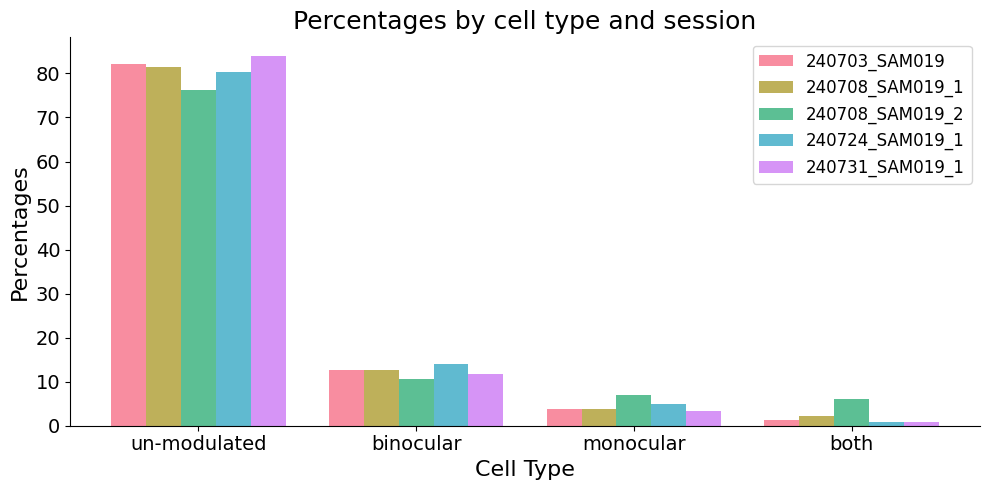

In [330]:
x = np.arange(len(categories))  # the label locations
num_datasets = len(cat_pcgt)
width = 0.8 / num_datasets  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))

palette = sns.color_palette('husl', 5)
# Plot each dataset
for i, percentages in enumerate(cat_pcgt):
    offset = (i - num_datasets / 2) * width + width / 2
    ax.bar(x + offset, percentages, width, color = palette[i], label=imaging_filenames[i], alpha=0.8)

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Percentages')
ax.set_title('Percentages by cell type and session')
ax.set_xticks(x)
ax.set_xticklabels(categories)
ax.legend()
# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# add legend
ax.legend(imaging_filenames, loc='upper right')

fig.tight_layout()
plt.show()

# Modulation pulled together for all sessions with error bars

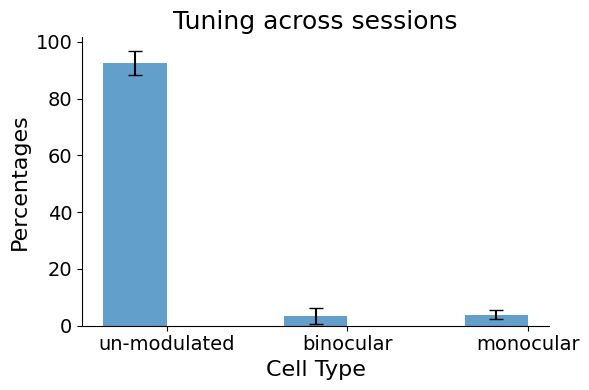

un-modulated (SpikeData): 92.57692770629053 ± 4.178933142655456
un-modulated (DffData): 81.87633731904127 ± 3.548718033033929
binocular (SpikeData): 3.5077928403279484 ± 2.757026638810103
binocular (DffData): 12.48371895297105 ± 2.937242438204074
monocular (SpikeData): 3.915279453381516 ± 1.65656271572385
monocular (DffData): 5.63994372798768 ± 1.7384616173618765


In [56]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Example data
categories = ['un-modulated', 'binocular', 'monocular']

# Function to compute counts and percentages
def compute_counts_and_percentages(Data):
    cat_count = []
    for D in Data:
        type = D.stats['type']
        counts = [type.count(cat) for cat in categories]
        cat_count.append(counts)

    cat_pcgt = []
    for count in cat_count:
        total_counts = sum(count)
        percentages = [i / total_counts * 100 for i in count]
        cat_pcgt.append(percentages)
    
    return np.array(cat_pcgt)

# Compute counts and percentages for both datasets
cat_pcgt_spikes = compute_counts_and_percentages(OutData)
cat_pcgt_dff = compute_counts_and_percentages(DffData)

# Calculate average percentages and standard deviation for error bars
averages_spikes = np.mean(cat_pcgt_spikes, axis=0)
std_devs_spikes = np.std(cat_pcgt_spikes, axis=0)

averages_dff = np.mean(cat_pcgt_dff, axis=0)
std_devs_dff = np.std(cat_pcgt_dff, axis=0)

x = np.arange(len(categories))  # the label locations
width = 0.35  # the width of the bars

fig, ax = plt.subplots(figsize=(6, 4))

# Plot the bar chart with error bars for SpikeData
rects1 = ax.bar(x - width/2, averages_spikes, width, yerr=std_devs_spikes, capsize=5, label='SpikeData', alpha=0.7)

# # Plot the bar chart with error bars for DffData
# rects2 = ax.bar(x + width/2, averages_dff, width, yerr=std_devs_dff, capsize=5, label='DffData', alpha=0.7)

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Cell Type')
ax.set_ylabel('Percentages')
ax.set_title('Tuning across sessions')
ax.set_xticks(x)
ax.set_xticklabels(categories)

# splines removed
# Remove top and right borders

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
plt.show()

# Print each category with its average and standard deviation for both datasets
for i, cat in enumerate(categories):
    print(f'{cat} (SpikeData): {averages_spikes[i]} ± {std_devs_spikes[i]}')
    print(f'{cat} (DffData): {averages_dff[i]} ± {std_devs_dff[i]}')
    



# Now I want to have the RF plot of the cells that are modulated

In [39]:
preferred_angle = []

for D in Data:
    
    # get cells that are not un-reliable
    reliable = np.array(D.stats['type']) != 'un-reliable'
    preferred_angle.append(np.array(D.stats['preferred_angle'])[reliable])
    
# format preferred_angle so that its good
# choose a palette of five different colors
palette = sns.color_palette('husl', 5)

# plot violin plot of all the sessions with their preferred angle
plt.figure(figsize=(10, 6))
sns.violinplot(data=preferred_angle, orient='h', palette=palette, alpha=0.8, inner_kws=dict(box_width=15, whis_width=2, color=".8"))

# y axia is the name of the sessions
plt.yticks(ticks=np.arange(len(imaging_filenames)), labels=imaging_filenames)
# remove splines
sns.despine()
plt.xlabel('Preferred Angle')
# # show the mean of the preferred angle for every session
# sns.swarmplot(data=preferred_angle, orient='h', palette=palette, alpha=0.8)

NameError: name 'sns' is not defined

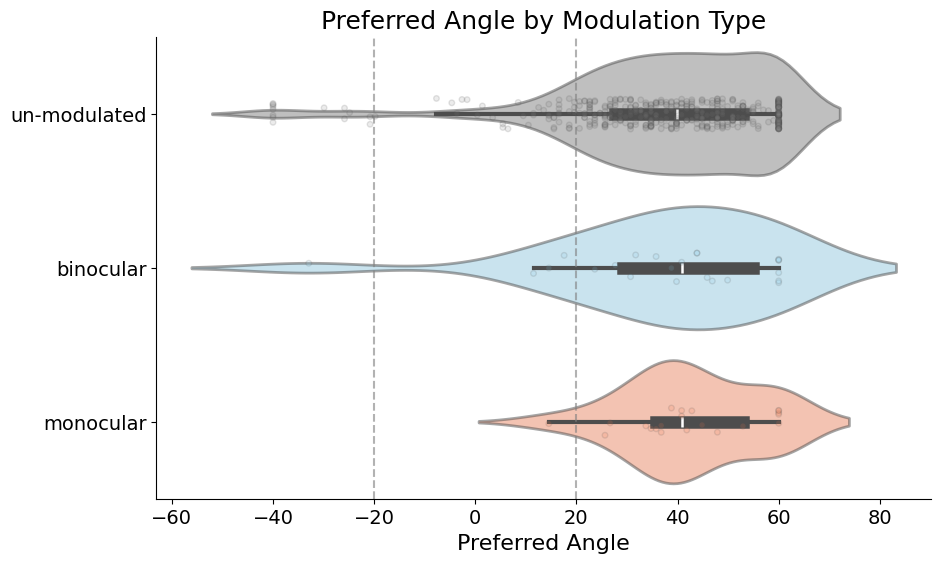

In [28]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Extract preferred_angle for each modulation type
unmodulated_RF = []
binocular_RF = []
monocular_RF = []

for D in OutData:
    for cell in range(D.dFF.shape[0]):
        type = D.stats['type'][cell]
        preferred_angle = D.stats['preferred_angle'][cell]

        if type == 'un-reliable':
            continue

        if type == 'un-modulated':
            unmodulated_RF.append(preferred_angle)
        elif type == 'binocular':
            binocular_RF.append(preferred_angle)
        elif type == 'monocular':
            monocular_RF.append(preferred_angle)

# Prepare data for plotting
data = [unmodulated_RF, binocular_RF, monocular_RF]
categories = ['un-modulated', 'binocular', 'monocular']
palette = ['gray', 'skyblue', 'coral']

# Create horizontal violin plot
plt.figure(figsize=(10, 6))
sns.stripplot(data=data, orient='h', palette=palette, s=4, alpha=0.15, jitter=True, linewidth=1)
sns.violinplot(data=data, orient='h', palette=palette, fill=True, alpha=0.5, linewidth=2)
plt.axvline(x=20, color='gray', linestyle='--', alpha=0.6)
plt.axvline(x=-20, color='gray', linestyle='--', alpha=0.6)
plt.yticks(ticks=np.arange(len(categories)), labels=categories)
plt.xlabel('Preferred Angle')
plt.title('Preferred Angle by Modulation Type')
# get spines of up and right and left removed
sns.despine()
plt.show()

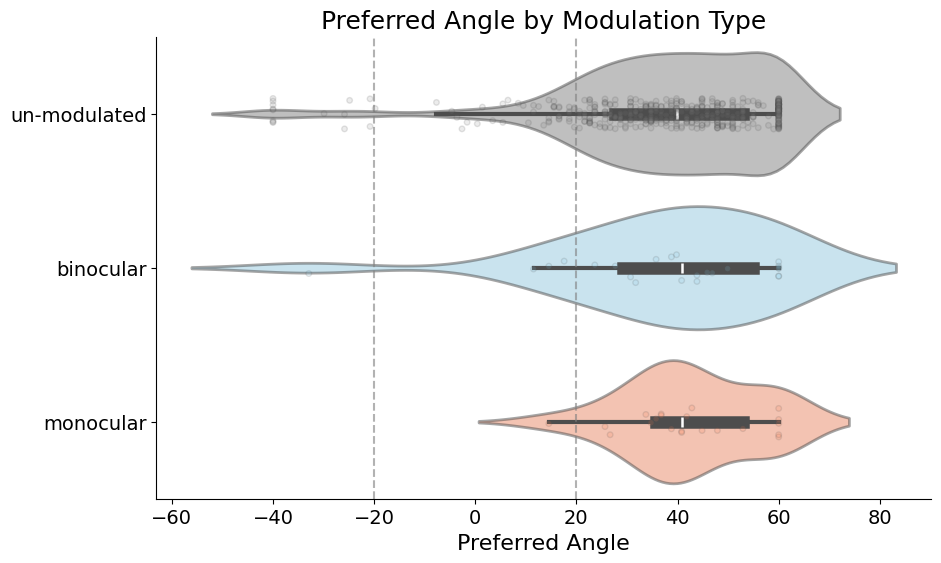

Kolmogorov-Smirnov test between un-modulated and binocular: KS Statistic = 0.0697861231047294, p-value = 0.9995961796388979
Kolmogorov-Smirnov test between un-modulated and monocular: KS Statistic = 0.20125371164632136, p-value = 0.34329528866301634


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

# Extract preferred_angle for each modulation type
unmodulated_RF = []
binocular_RF = []
monocular_RF = []

for D in OutData:
    for cell in range(D.dFF.shape[0]):
        type = D.stats['type'][cell]
        preferred_angle = D.stats['preferred_angle'][cell]

        if type == 'un-reliable':
            continue

        if type == 'un-modulated':
            unmodulated_RF.append(preferred_angle)
        elif type == 'binocular':
            binocular_RF.append(preferred_angle)
        elif type == 'monocular':
            monocular_RF.append(preferred_angle)

# Prepare data for plotting
data = [unmodulated_RF, binocular_RF, monocular_RF]
categories = ['un-modulated', 'binocular', 'monocular']
palette = ['gray', 'skyblue', 'coral']

# Perform Kolmogorov-Smirnov test
ks_stat_binocular, p_value_binocular = ks_2samp(unmodulated_RF, binocular_RF)
ks_stat_monocular, p_value_monocular = ks_2samp(unmodulated_RF, monocular_RF)

# Create horizontal violin plot
plt.figure(figsize=(10, 6))
sns.stripplot(data=data, orient='h', palette=palette, s=4, alpha=0.15, jitter=True, linewidth=1)
sns.violinplot(data=data, orient='h', palette=palette, fill=True, alpha=0.5, linewidth=2)
plt.axvline(x=20, color='gray', linestyle='--', alpha=0.6)
plt.axvline(x=-20, color='gray', linestyle='--', alpha=0.6)
plt.yticks(ticks=np.arange(len(categories)), labels=categories)
plt.xlabel('Preferred Angle')
plt.title('Preferred Angle by Modulation Type')

# Plot significant lines if p-value < 0.05
if p_value_binocular < 0.05:
    plt.plot([-30, -25], [1, 1], color='black', lw=2)
    plt.text(-27.5, 1.1, '*', ha='center', va='bottom', color='black', fontsize=16)

if p_value_monocular < 0.05:
    plt.plot([-30, -25], [2, 2], color='black', lw=2)
    plt.text(-27.5, 2.1, '*', ha='center', va='bottom', color='black', fontsize=16)

# Remove spines
sns.despine()
plt.show()

# Print KS test results
print(f'Kolmogorov-Smirnov test between un-modulated and binocular: KS Statistic = {ks_stat_binocular}, p-value = {p_value_binocular}')
print(f'Kolmogorov-Smirnov test between un-modulated and monocular: KS Statistic = {ks_stat_monocular}, p-value = {p_value_monocular}')

In [30]:
from scipy.stats import ks_2samp

# Perform Kolmogorov-Smirnov test
ks_stat_binocular, p_value_binocular = ks_2samp(unmodulated_RF, binocular_RF)
ks_stat_monocular, p_value_monocular = ks_2samp(unmodulated_RF, monocular_RF)
# run also for binocular and monocular
ks_stat_binocular_monocular, p_value_binocular_monocular = ks_2samp(binocular_RF, monocular_RF)

print(f'Kolmogorov-Smirnov test between un-modulated and binocular: KS Statistic = {ks_stat_binocular}, p-value = {p_value_binocular}')
print(f'Kolmogorov-Smirnov test between un-modulated and monocular: KS Statistic = {ks_stat_monocular}, p-value = {p_value_monocular}')
print(f'Kolmogorov-Smirnov test between binocular and monocular: KS Statistic = {ks_stat_binocular_monocular}, p-value = {p_value_binocular_monocular}')

Kolmogorov-Smirnov test between un-modulated and binocular: KS Statistic = 0.0697861231047294, p-value = 0.9995961796388979
Kolmogorov-Smirnov test between un-modulated and monocular: KS Statistic = 0.20125371164632136, p-value = 0.34329528866301634
Kolmogorov-Smirnov test between binocular and monocular: KS Statistic = 0.20496894409937888, p-value = 0.6532231670067591


 Current sessions:  D:/data-distance-coding-project/processed-data\240731_SAM019_1

Text(0.5, 1.0, 'Receptive Field vs Preferred Distance')

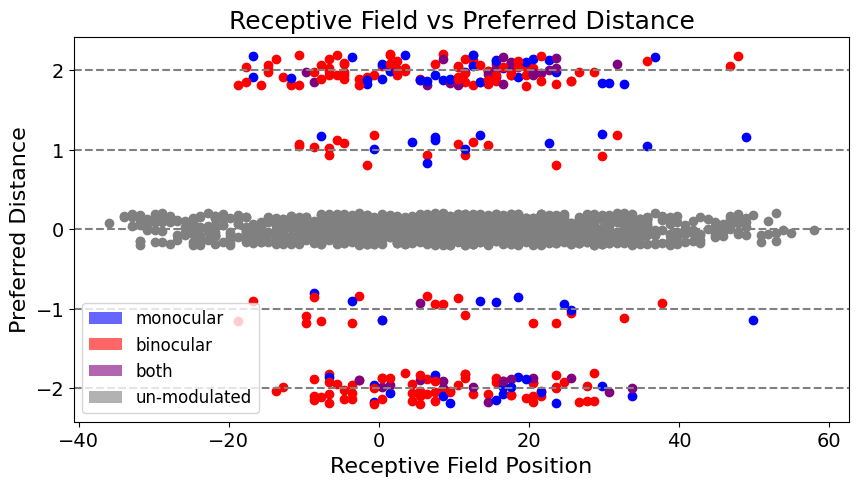

In [16]:
import random
from matplotlib.patches import Patch

# Create a mapping dictionary
distance_mapping = {0: 0, 1: -2, 2: -1, 3: 1, 4:2}
# Function to map preferred_distance using the dictionary
def map_preferred_distance(preferred_distance):
    return distance_mapping.get(preferred_distance, preferred_distance)

# map type to color
type_color = {'binocular': 'r', 'monocular': 'b', 'both': 'purple', 'un-modulated': 'gray'}
def map_type_to_color(type):
    return type_color.get(type, type)

plt.figure(figsize=(10, 5))

print('\r Current sessions: ', D.path, end="")
population_distance = []

for D in SpikeData:
    for cell in range(D.dFF.shape[0]):
        
        type = D.stats['type'][cell]
        preferred_distance = D.stats['preferred_distance'][cell]
        receptive_field = D.stats['preferred_angle'][cell]
        
        if type == 'un-reliable':
            continue
        
        distance_remapped = map_preferred_distance(preferred_distance)
        
        if type != 'un-modulated':
            population_distance.append(distance_remapped)
            
        color = map_type_to_color(type)
        
        plt.scatter(receptive_field, distance_remapped + random.uniform(-.2, .2), color=color)

# add horizontal lines for -2, -1, 0, 1, 2
for i in range(-2, 3):
    plt.axhline(y=i, color='gray', linestyle='--')
    
legend_elements = [Patch(facecolor='blue', alpha=0.6, label='monocular'),
                       Patch(facecolor='red', alpha=0.6,
                             label='binocular'),
                          Patch(facecolor='purple', alpha=0.6,
                                label='both'),
                            Patch(facecolor='gray', alpha=0.6,
                                    label='un-modulated')]

plt.legend(handles=legend_elements)
plt.xlabel('Receptive Field Position')
plt.ylabel('Preferred Distance')
plt.title('Receptive Field vs Preferred Distance')

In [ ]:
# Counts by cell type and modulation

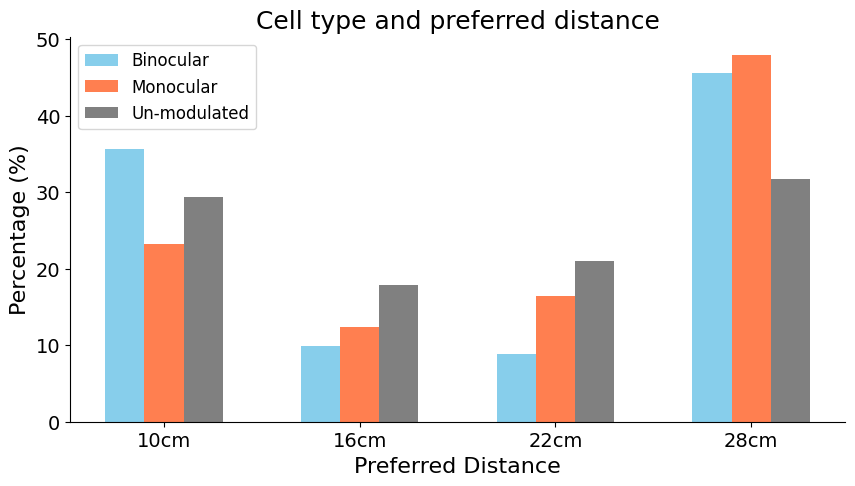

In [25]:
# Example data
categories = [1, 2, 3, 4]

pop_distance_monocular = []
pop_distance_binocular = []
pop_distance_unmodulated = []

for D in SpikeData:
    
    for cell in range(D.dFF.shape[0]):
        
        type = D.stats['type'][cell]
        
        if type == 'un-reliable':
            continue
        elif type == 'un-modulated':
            pop_distance_unmodulated.append(D.stats['preferred_distance'][cell])
        elif type == 'monocular':
            pop_distance_monocular.append(D.stats['preferred_distance'][cell])
        elif type == 'binocular':
            pop_distance_binocular.append(D.stats['preferred_distance'][cell])
   
# do bar plot with the two types for each category
# Calculate counts
counts_distance_monocular = [pop_distance_monocular.count(cat) for cat in categories]
counts_distance_binocular = [pop_distance_binocular.count(cat) for cat in categories]
counts_distance_unmodulated = [pop_distance_unmodulated.count(cat) for cat in categories]

# same with pctg
total_counts_monocular = sum(counts_distance_monocular)
total_counts_binocular = sum(counts_distance_binocular)
total_counts_unmodulated = sum(counts_distance_unmodulated)

percentages_monocular = [i / total_counts_monocular * 100 for i in counts_distance_monocular]
percentages_binocular = [i / total_counts_binocular * 100 for i in counts_distance_binocular]
percentages_unmodulated = [i / total_counts_unmodulated * 100 for i in counts_distance_unmodulated]

# Do barplot
x = np.arange(len(categories))  # the label locations
width = 0.2  # the width of the bars

fig, ax = plt.subplots(figsize=(10, 5))
rects1 = ax.bar(x - width, percentages_binocular, width, label='Binocular', color='skyblue')
rects2 = ax.bar(x, percentages_monocular, width, label='Monocular', color='coral')
rects3 = ax.bar(x+width, percentages_unmodulated, width, label='Un-modulated', color='gray')

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_xlabel('Preferred Distance')
ax.set_ylabel('Percentage (%)')
ax.set_title('Cell type and preferred distance')
ax.set_xticks(x)
ax.set_xticklabels(['10cm', '16cm', '22cm', '28cm'])
ax.legend()

# Remove top and right borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

In [337]:
# Now I want to see how the cell response changes from one eye to two eye

In [63]:

from scipy.ndimage import gaussian_filter1d
ratio = []
receptive_field = []
type = []

for D in SpikeData:
    
    reliable_cells = np.where(np.array(D.stats['type']) != 'un-reliable')[0]

    for cell in reliable_cells:
    
        # get the mean response of the cell to one eye and two eye block
        one_eye = D.get_all_traces(cell, block='one eye', mean_trace=True)[0]
        two_eye = D.get_all_traces(cell, block='two eye', mean_trace=True)[0]
        
        is_one_eye_reliable = D.stats['is_reliable_one_eye'][cell]
        is_two_eye_reliable = D.stats['is_reliable_two_eye'][cell]
        
        if is_two_eye_reliable and is_one_eye_reliable:
            receptive_field_two = D.compute_receptive_field(cell, block='two eye')
            receptive_field_one = D.compute_receptive_field(cell, block='one eye')
        elif is_two_eye_reliable and not is_one_eye_reliable:
            receptive_field_two = D.compute_receptive_field(cell, block='two eye')
            receptive_field_one = receptive_field_two
        elif is_one_eye_reliable and not is_two_eye_reliable:
            receptive_field_one = D.compute_receptive_field(cell, block='one eye')
            receptive_field_two = receptive_field_one
        else:
            print('Cell is not reliable in any block')
            
        # the max value after rolling a 1d gaussian filter of sigma 3
        one_eye_max = gaussian_filter1d(one_eye, 3)[receptive_field_one]
        two_eye_max = gaussian_filter1d(two_eye, 3)[receptive_field_two]
        
        if D.stats['type'][cell] != 'both':
            ratio.append((two_eye_max-one_eye_max) / (one_eye_max + two_eye_max))
            receptive_field.append(D.angle_range[receptive_field_two])
            type.append(D.stats['type'][cell])

(array([ 4.,  3.,  4.,  9., 10., 14., 21., 22., 12., 22., 17., 26., 34.,
        39., 50., 47., 35., 45., 50., 45., 48., 56., 34., 49., 49., 58.,
        55., 54., 51., 55., 31., 45., 42., 39., 33., 38., 31., 39., 31.,
        28., 34., 27., 29., 19., 20., 29., 15., 10.,  6.,  5.]),
 array([-0.93196333, -0.89423151, -0.8564997 , -0.81876789, -0.78103608,
        -0.74330427, -0.70557245, -0.66784064, -0.63010883, -0.59237702,
        -0.55464521, -0.5169134 , -0.47918158, -0.44144977, -0.40371796,
        -0.36598615, -0.32825434, -0.29052253, -0.25279071, -0.2150589 ,
        -0.17732709, -0.13959528, -0.10186347, -0.06413166, -0.02639984,
         0.01133197,  0.04906378,  0.08679559,  0.1245274 ,  0.16225922,
         0.19999103,  0.23772284,  0.27545465,  0.31318646,  0.35091827,
         0.38865009,  0.4263819 ,  0.46411371,  0.50184552,  0.53957733,
         0.57730914,  0.61504096,  0.65277277,  0.69050458,  0.72823639,
         0.7659682 ,  0.80370002,  0.84143183,  0.87916364,

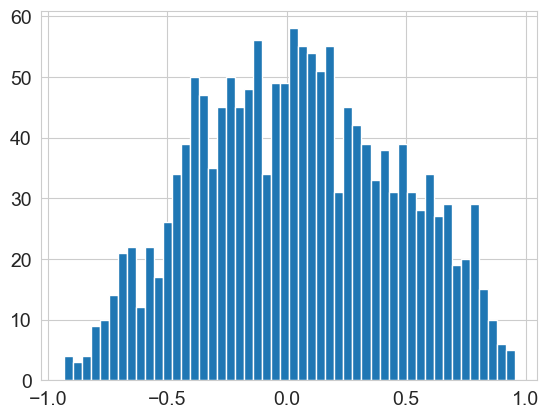

In [29]:
# make a histogram of the ratio
plt.figure()
plt.hist(ratio, bins=50)

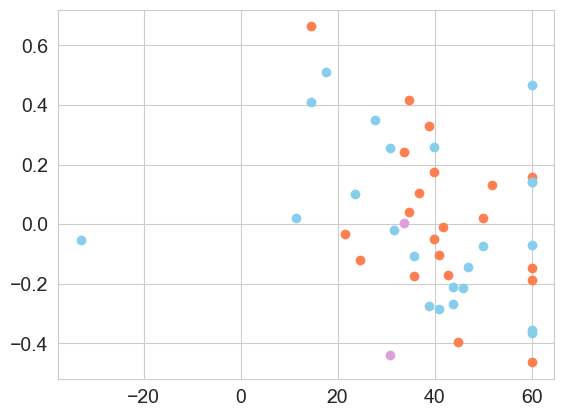

In [26]:
plt.figure()

# scatter receptive field vas ratio and color by type
colors = {'un-modulated': 'gray', 'binocular': 'skyblue', 'monocular': 'coral', 'both': 'plum'}
for t in ['monocular', 'binocular', 'both']:
    idx = np.where(np.array(type) == t)
    plt.scatter(np.array(receptive_field)[idx], np.array(ratio)[idx], c=colors[t], label=t)

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_23196\1092679666.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=type, y=ratio, palette=colors)


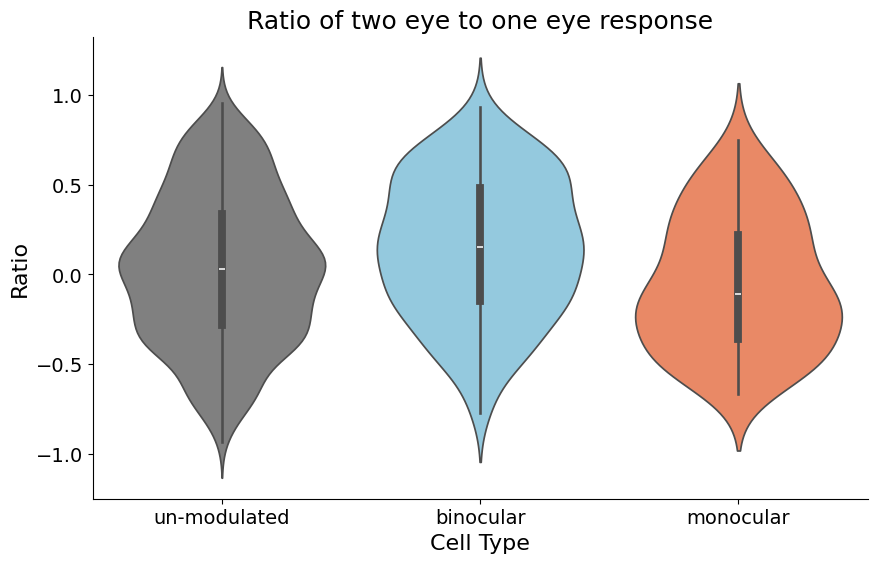

In [65]:
# Print violin plots of the ratio for each class
import seaborn as sns
categories = ['un-modulated', 'binocular', 'monocular']
palette = ['gray', 'skyblue', 'coral']
plt.figure(figsize=(10, 6))
sns.violinplot(x=type, y=ratio, palette=colors)
plt.xlabel('Cell Type')
plt.ylabel('Ratio')
plt.title('Ratio of two eye to one eye response')
sns.despine()
plt.show()

In [ ]:
# do whatever you want

In [ ]:
# plot sinus and cosinus of the receptive field
plt.figure()
plt.scatter(np.cos(receptive_field), np.sin(receptive_field), c=ratio)
plt.colorbar()

C:\Users\acostamendoza\AppData\Local\Temp\ipykernel_2760\1405500623.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=type, y=ratio, palette=colors)


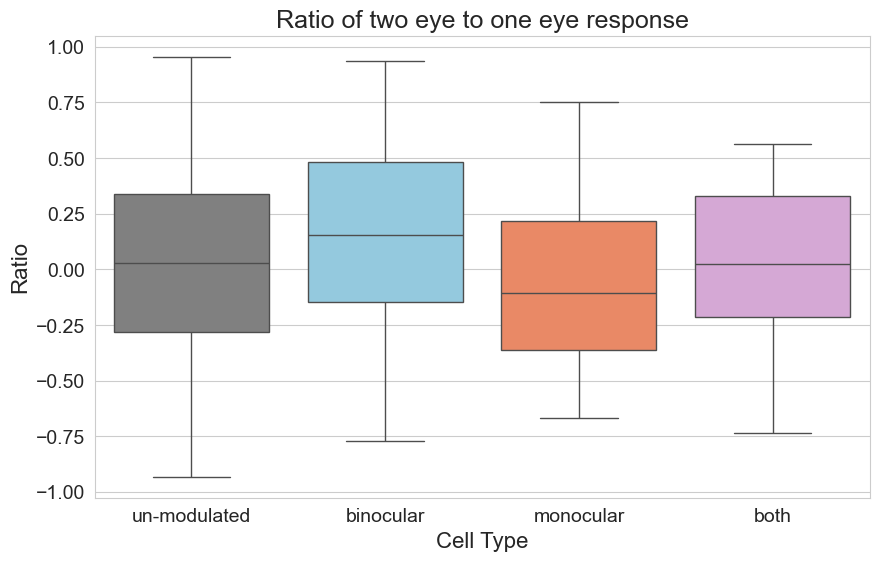

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

# Define the colors for each cell type
colors = {'un-modulated': 'gray', 'binocular': 'skyblue', 'monocular': 'coral', 'both': 'plum'}

# Create a boxplot of the ratio for each cell type
plt.figure(figsize=(10, 6))
sns.boxplot(x=type, y=ratio, palette=colors)
plt.xlabel('Cell Type')
plt.ylabel('Ratio')
plt.title('Ratio of two eye to one eye response')
plt.show()